# BreathMetrics test
Demo of `src/rsp/breathmetrics.py` on one cohort 3 cagemate session, at 400 Hz (the classifiers' rate).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[2]  # repo root (notebook lives in src/<pkg>/test)
sys.path.insert(0, str(ROOT))
H5 = ROOT / "exports/cagemate_h5/cohort3_bla_cohort2_CM/11_4_d_CM_11_3_s_20260729_125055.h5"
from src.rsp import resp_processing as rp
from src.rsp import breathmetrics as bmx

FS = 400
resp, t = rp.preprocess_resp(rp.load_raw_resp(H5), target_fs=FS)

## `bmObject.estimateAllFeatures`
Peaks come from `rp.detect_breaths` (`peak_method='src'`). The first call prints the unverified features.

In [2]:
bm = bmx.bmObject(resp, FS, "rodentAirflow")
bm.estimateAllFeatures()  # peak_method='src' is the default
print(f"{len(bm.inhalePeaks)} breaths, {bm.nOnsetLocalFallbacks} half-cycles used the local crossing level")

BreathMetrics: these features are ESTIMATED, not measured (consider dropping):
  - Average Inhale Volume: integral of uncalibrated nasal pressure (~flow^2), not air volume
  - Average Exhale Volume: integral of uncalibrated nasal pressure (~flow^2), not air volume
  - Average Tidal Volume: integral of uncalibrated nasal pressure (~flow^2), not air volume
  - Minute Ventilation: integral of uncalibrated nasal pressure (~flow^2), not air volume
  - Coefficient of Variation of Breath Volumes: integral of uncalibrated nasal pressure (~flow^2), not air volume
  - Average Peak Inspiratory Flow: uncalibrated pressure amplitude; only comparable within a recording
  - Average Peak Expiratory Flow: uncalibrated pressure amplitude; only comparable within a recording
  - Average Inhale Duration: depends on onsets at an estimated zero-flow baseline (a guess for pressure data)
  - Average Exhale Duration: depends on onsets at an estimated zero-flow baseline (a guess for pressure data)
  - Duty Cycle

4651 breaths, 60 half-cycles used the local crossing level


## Breath landmarks
Peaks/troughs, plus inhale and exhale onsets, over 3 s.

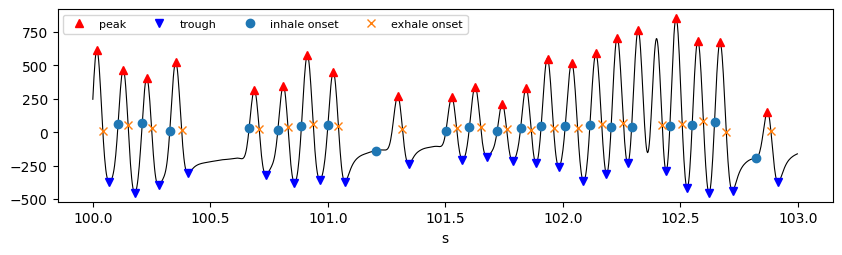

In [3]:
x, tt = bm.baselineCorrectedRespiration, bm.time
w = (tt >= 100) & (tt < 103)
sel = lambda idx: [i for i in np.asarray(idx, dtype=int) if w[i]]
plt.figure(figsize=(10, 2.5)); plt.plot(tt[w], x[w], color="k", lw=0.8)
for idx, style, lab in [(bm.inhalePeaks, "r^", "peak"), (bm.exhaleTroughs, "bv", "trough"),
                        (bm.inhaleOnsets, "o", "inhale onset"), (bm.exhaleOnsets, "x", "exhale onset")]:
    i = sel(idx); plt.plot(tt[i], x[i], style, label=lab)
plt.legend(fontsize=8, ncol=4); plt.xlabel("s"); plt.show()

## `peak_method`: src vs legacy
Legacy is the original BreathMetrics extrema search (only accepts peaks above the session mean + std/2).

In [4]:
for method in ["src", "legacy"]:
    b = bmx.bmObject(resp, FS, "rodentAirflow"); b.estimateAllFeatures(peak_method=method)
    print(f"{method:>6}: {len(b.inhalePeaks):5d} breaths, {b.secondaryFeatures['Breathing Rate']:.2f} Hz")

   src:  4651 breaths, 7.46 Hz


legacy:  4453 breaths, 7.15 Hz


## `UNVERIFIED_FEATURES`
Secondary features that are estimated, not measured, and why. Reprint with `print_unverified_features()`.

In [5]:
import pandas as pd
feats = pd.Series(bm.secondaryFeatures, name="value").to_frame()
feats["unverified"] = feats.index.map(lambda k: bmx.UNVERIFIED_FEATURES.get(k, ""))
feats

,value,unverified
Breathing Rate,7.463375,
Average Inter-Breath Interval,0.133988,
Average Peak Inspiratory Flow,507.344701,uncalibrated pressure amplitude; only comparab...
Average Peak Expiratory Flow,-391.906748,uncalibrated pressure amplitude; only comparab...
Average Inhale Volume,17059.403437,integral of uncalibrated nasal pressure (~flow...
Average Exhale Volume,15680.976193,integral of uncalibrated nasal pressure (~flow...
Average Tidal Volume,32740.379631,integral of uncalibrated nasal pressure (~flow...
Minute Ventilation,244353.740366,integral of uncalibrated nasal pressure (~flow...
Duty Cycle of Inhale,0.401856,depends on onsets at an estimated zero-flow ba...
Duty Cycle of Inhale Pause,0.001890,"histogram heuristic, no ground truth; detector..."


## `bm_features`: window features
One fit per recording, then features per window. `tile_windows` covers the whole recording (dead-signal windows dropped).

In [6]:
from src.rsp import bm_features as bf

windows = bf.tile_windows(t, window_sec=2.0, signal=resp)
rows = bf.extract_features_from_windows(bm, windows, min_breaths_per_window=4)
print(f"{len(rows)} of {len(windows)} windows kept; supported columns: {bf.SUPPORTED_WINDOW_FEATURES}")
pd.DataFrame(rows).head(3)

302 of 306 windows kept; supported columns: ['n_breaths', 'breathing_rate_hz', 'mean_ibi_sec', 'cv_ibi']


,WindowID,Start,Stop,Duration,n_breaths,breathing_rate_hz,mean_ibi_sec,cv_ibi,mean_inhale_dur_sec,cv_inhale_dur,...,pct_breaths_with_inhale_pause,mean_inhale_pause_dur_sec,cv_inhale_pause_dur,inhale_pause_duty_cycle,pct_breaths_with_exhale_pause,mean_exhale_pause_dur_sec,cv_exhale_pause_dur,exhale_pause_duty_cycle,inhale_duty_cycle,exhale_duty_cycle
0,0,0.0,2.0,2.0,13,7.250755,0.137917,0.705585,0.053077,0.469255,...,0.0,0.0,NaN,0.0,0.076923,0.1050,NaN,0.058564,0.384848,0.587032
1,1,2.0,4.0,2.0,20,9.632446,0.103816,0.255970,0.048250,0.501039,...,0.0,0.0,NaN,0.0,0.000000,0.0000,NaN,0.000000,0.464766,0.482826
2,2,4.0,6.0,2.0,16,8.486563,0.117833,0.284317,0.063281,0.647606,...,0.0,0.0,NaN,0.0,0.062500,0.0675,NaN,0.035803,0.537040,0.434936


## `full_recording_feature_extraction`: features over time
`extract_recording_features` does load -> fit -> tile -> features for one H5. `step_sec` < `window_sec` gives overlapping windows; `WindowIndex` keeps time order.

{'n_windows_possible': 622, 'n_windows_kept': 606, 'onset_local_fallbacks': 60}


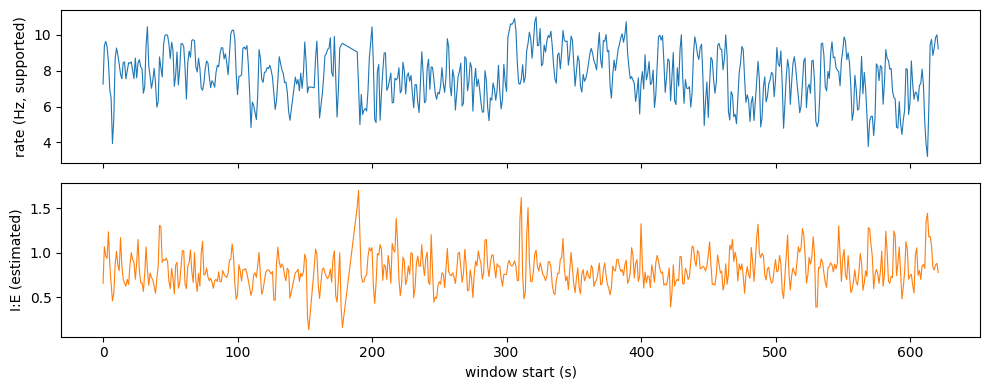

In [7]:
from src.rsp import full_recording_feature_extraction as fr

df, qc = fr.extract_recording_features(H5, window_sec=2.0, step_sec=1.0, Subject="11_4")
print({k: qc[k] for k in ["n_windows_possible", "n_windows_kept", "onset_local_fallbacks"]})
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(df.Start, df.breathing_rate_hz, lw=0.8); ax[0].set_ylabel("rate (Hz, supported)")
ax[1].plot(df.Start, df.ie_ratio, lw=0.8, color="tab:orange"); ax[1].set_ylabel("I:E (estimated)")
ax[1].set_xlabel("window start (s)"); plt.tight_layout(); plt.show()

## How to use
Batch: catalog the curated folder (`valence_rank_respiration`), filter, extract, save CSV + manifest. Or from a shell:
`python -m src.rsp.full_recording_feature_extraction --cohort cohort1_2025_aim1 --jobs 8`

In [8]:
import tempfile

cat = fr.build_catalog()                       # all cohorts; filter like any DataFrame
cat = cat[(cat.Cohort == "cohort1_2025_aim1") & (cat.Dataset == "rank")].head(2)
feats = fr.run(cat, out_dir=tempfile.mkdtemp(), window_sec=2.0)
meta = ["WindowIndex", "RecordingID", "Cohort", "Subject", "Rank", "Start"]
feats[meta + bf.SUPPORTED_WINDOW_FEATURES].head()  # drop the estimated features

  - dropped CM_s3_5_d3_6_20250623_160001_merged: short session (355 s), singleton cage
  - dropped RI2_s3_5_p5_4_nRB3_20250621_112618_merged: incomplete session (213 s), unpaired


wrote C:\Users\thoma\AppData\Local\Temp\tmpe91_e4jn\full-recording-features-2s.csv: 540 windows from 2 recordings
Supported features: ['n_breaths', 'breathing_rate_hz', 'mean_ibi_sec', 'cv_ibi']; all other feature columns are estimated.


,WindowIndex,RecordingID,Cohort,Subject,Rank,Start,n_breaths,breathing_rate_hz,mean_ibi_sec,cv_ibi
0,0,CM_s1_1_d1_2_20250623_111352_merged,cohort1_2025_aim1,1_1,Subordinate,0.0,11,5.305040,0.188500,0.380024
1,1,CM_s1_1_d1_2_20250623_111352_merged,cohort1_2025_aim1,1_1,Subordinate,2.0,18,9.201624,0.108676,0.138726
2,2,CM_s1_1_d1_2_20250623_111352_merged,cohort1_2025_aim1,1_1,Subordinate,4.0,17,8.499336,0.117656,0.292644
3,3,CM_s1_1_d1_2_20250623_111352_merged,cohort1_2025_aim1,1_1,Subordinate,6.0,20,9.743590,0.102632,0.211542
4,4,CM_s1_1_d1_2_20250623_111352_merged,cohort1_2025_aim1,1_1,Subordinate,8.0,21,10.498688,0.095250,0.059215
